# Model Validation & MLOps Capstone for a PD Model

A credit model is not ready to use just because it scores well on a test set. Before a model-risk committee signs off, an independent validator has to show that it ranks borrowers well, that its PDs are at the right level, that the population it will score looks like the one it was built on, and that every result can be reproduced. This notebook runs that full review on a real PD model.

**What it does.** It builds a LightGBM application PD model with monotone constraints and takes it through the full independent-validation and MLOps cycle.

That means experiment tracking and a model registry in MLflow, a champion–challenger comparison, and the standard validation tests: discrimination with confidence intervals, calibration, stability, segment performance, sensitivity, monotonicity and fairness.

It then monitors population stability on the real production population, summarises everything in traffic lights and generates a model card automatically.

**Data.** Home Credit Default Risk (Kaggle): 307,511 labelled applications for development, and **48,744 unlabelled applications** from the competition's test file, used as the first month of "production" for drift monitoring.

**Methods.** A DuckDB feature pipeline, LightGBM with monotonic constraints and Platt calibration (champion) against a logistic regression without WoE (challenger), and MLflow tracking, model logging and registry.

The tests include bootstrap AUC and a DeLong-style comparison, Hosmer–Lemeshow, Brier, ECE and calibration-in-the-large, PSI and characteristic stability indices, ICE monotonicity, stressed-input sensitivity and the adverse-impact ratio.

**Key output.** A validation scorecard with green, amber and red ratings, the drift report for the production population, and a model card ready for a model-risk committee.

## 1. What model validation has to show

Under U.S. supervisory guidance on model risk (SR 11-7), and the similar expectations of development-bank risk functions, a PD model can be approved only after an **independent** review. The review covers seven areas:

| Area | Question | Test here |
|---|---|---|
| Conceptual soundness | Does the model make economic sense? | monotonic constraints, ICE test (a reversal below 0.1 pp of PD is treated as immaterial), sensitivity to stressed inputs |
| Discrimination | Does it rank good from bad? | AUC/Gini with bootstrap CI; champion vs challenger |
| Calibration | Are PD levels right? | calibration-in-the-large, Hosmer–Lemeshow, ECE, Brier |
| Stability | Is the population it will score like the one it was built on? | PSI on the score, CSI on each characteristic |
| Segment performance | Does it work for every product and customer type? | AUC and calibration by segment |
| Fairness | Do outcomes differ by protected group? | adverse-impact ratio by gender |
| Governance | Can the result be reproduced and audited? | MLflow run, logged model, registry stage, model card |

The traffic lights use typical industry thresholds: Gini is green at 0.40 or more and red below 0.30; PSI is green below 0.10 and red at 0.25 or more; the adverse-impact ratio is green at 0.80 or more.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_ENABLE_ASYNC_LOGGING", "false")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import duckdb
import lightgbm as lgb
import mlflow
from mlflow.models import infer_signature
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 7
COMPETITION = "home-credit-default-risk"
FILES = [
    "application_train.csv",
    "application_test.csv",
    "bureau.csv",
    "previous_application.csv",
    "installments_payments.csv",
]
TARGET_APPROVAL = 0.80
THRESH = {
    "gini": (0.40, 0.30),
    "psi": (0.10, 0.25),
    "air": (0.80, 0.70),
    "ece_pp": (1.0, 2.0),
}

print(
    f"mlflow {mlflow.__version__} · lightgbm {lgb.__version__} · duckdb"
    f" {duckdb.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

mlflow 3.17.1 · lightgbm 4.7.0 · duckdb 1.5.6 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


# --- Kaggle downloads
# The kaggle package authenticates with KAGGLE_API_TOKEN (read from .env above)
# or with
# ~/.kaggle/access_token / ~/.kaggle/kaggle.json. It is imported here, after
# load_dotenv, on purpose.
import zipfile


def kaggle_api():
    from kaggle.api.kaggle_api_extended import KaggleApi

    api = KaggleApi()
    api.authenticate()
    return api


def kaggle_file(ref, filename, competition=False):
    """
    Download one file of a Kaggle dataset or competition into data/ (once) and
    return its local path.
    """
    target = DATA_DIR / filename
    if target.exists():
        return target
    api = kaggle_api()
    if competition:
        api.competition_download_file(ref, filename, path=DATA_DIR, quiet=True)
    else:
        api.dataset_download_file(ref, filename, path=DATA_DIR, quiet=True)
    zipped = DATA_DIR / f"{Path(filename).name}.zip"
    # large files arrive zipped
    if zipped.exists():
        with zipfile.ZipFile(zipped) as z:
            z.extractall(DATA_DIR)
        zipped.unlink()
    if not target.exists():
        raise FileNotFoundError(
            f"{filename} not found after download from {ref}"
        )
    return target

## 3. Feature pipeline (identical for development and production)

One SQL query builds the features for any application table, so development and production are scored by exactly the same code, which is the first thing an MLOps reviewer checks.

In [3]:
paths = {f: kaggle_file(COMPETITION, f, competition=True) for f in FILES}
con = duckdb.connect()
con.execute("SET enable_progress_bar = false")
for f, p in paths.items():
    con.execute(
        f"CREATE OR REPLACE VIEW {f.split('.')[0]} AS SELECT * FROM"
        f" read_csv_auto('{p.as_posix()}', sample_size=-1)"
    )
con.execute(
    """
CREATE OR REPLACE TABLE hist AS
WITH bur AS (SELECT SK_ID_CURR, COUNT(*) AS bureau_n_credits,
                    SUM(COALESCE(AMT_CREDIT_SUM_DEBT, 0)) / NULLIF(SUM(AMT_CREDIT_SUM), 0) AS bureau_debt_to_credit,
                    MAX(CREDIT_DAY_OVERDUE) AS bureau_max_days_overdue FROM bureau GROUP BY 1),
     prev AS (SELECT SK_ID_CURR, COUNT(*) AS prev_n_applications,
                     AVG(CASE WHEN NAME_CONTRACT_STATUS = 'Refused' THEN 1 ELSE 0 END) AS prev_refused_share FROM previous_application GROUP BY 1),
     inst AS (SELECT SK_ID_CURR, AVG(CASE WHEN DAYS_ENTRY_PAYMENT > DAYS_INSTALMENT THEN 1 ELSE 0 END) AS inst_late_share,
                     AVG(GREATEST(DAYS_ENTRY_PAYMENT - DAYS_INSTALMENT, 0)) AS inst_avg_days_late,
                     AVG(CASE WHEN AMT_PAYMENT < 0.99 * AMT_INSTALMENT THEN 1 ELSE 0 END) AS inst_underpaid_share
              FROM installments_payments GROUP BY 1)
SELECT * FROM bur FULL JOIN prev USING (SK_ID_CURR) FULL JOIN inst USING (SK_ID_CURR)"""
)


def build_features(table, labelled):
    target = "a.TARGET," if labelled else "NULL AS TARGET,"
    return con.execute(
        f"""
        SELECT a.SK_ID_CURR, {target} a.CODE_GENDER, a.NAME_CONTRACT_TYPE AS contract_type, a.NAME_INCOME_TYPE AS income_type,
               a.EXT_SOURCE_1, a.EXT_SOURCE_2, a.EXT_SOURCE_3, -a.DAYS_BIRTH / 365.25 AS age_years,
               CASE WHEN a.DAYS_EMPLOYED = 365243 THEN NULL ELSE -a.DAYS_EMPLOYED / 365.25 END AS years_employed,
               a.AMT_INCOME_TOTAL AS income, a.AMT_CREDIT AS credit, a.AMT_ANNUITY AS annuity,
               a.AMT_CREDIT / NULLIF(a.AMT_GOODS_PRICE, 0) AS credit_to_goods, a.AMT_ANNUITY / NULLIF(a.AMT_INCOME_TOTAL, 0) AS annuity_to_income,
               a.AMT_CREDIT / NULLIF(a.AMT_ANNUITY, 0) AS credit_term_proxy, a.REGION_RATING_CLIENT_W_CITY AS region_rating,
               -a.DAYS_ID_PUBLISH / 365.25 AS years_since_id_change, a.OWN_CAR_AGE AS car_age,
               h.* EXCLUDE (SK_ID_CURR)
        FROM {table} a LEFT JOIN hist h USING (SK_ID_CURR)
        ORDER BY a.SK_ID_CURR"""
        # fixed row order: DuckDB joins are parallel, so the split must not depend
        # on it
    ).df()


dev = build_features("application_train", True)
prod = build_features("application_test", False)
FEATURES = [
    c
    for c in dev.columns
    if c
    not in (
        "SK_ID_CURR",
        "TARGET",
        "CODE_GENDER",
        "contract_type",
        "income_type",
    )
]
# one numeric type: clean model signature
dev[FEATURES], prod[FEATURES] = dev[FEATURES].astype(float), prod[
    FEATURES
].astype(float)
print(
    f"development {len(dev):,} (default {dev['TARGET'].mean():.2%}) ·"
    f" production {len(prod):,} unlabelled · {len(FEATURES)} features"
)

development 307,511 (default 8.07%) · production 48,744 unlabelled · 22 features


## 4. Champion and challenger, tracked in MLflow

The experiment is stored in a local MLflow database inside `data/` (it is not part of the deliverables). Every run logs its parameters, metrics and the fitted model; the champion is registered and promoted with an alias, so the exact object that was validated is the one that would be deployed.

In [4]:
import logging

# keep the notebook output readable
logging.getLogger("mlflow").setLevel(logging.ERROR)
mlflow.set_tracking_uri(f"sqlite:///{(DATA_DIR / 'mlflow.db').as_posix()}")
EXP = "G07_pd_validation"
if mlflow.get_experiment_by_name(EXP) is None:
    mlflow.create_experiment(
        EXP, artifact_location=(DATA_DIR / "mlartifacts").resolve().as_uri()
    )
mlflow.set_experiment(EXP)

train, rest = train_test_split(
    dev, test_size=0.4, stratify=dev["TARGET"], random_state=SEED
)
calib, test = train_test_split(
    rest, test_size=0.5, stratify=rest["TARGET"], random_state=SEED
)
y_tr, y_ca, y_te = (
    d["TARGET"].astype(int).to_numpy() for d in (train, calib, test)
)
MONO = {
    "EXT_SOURCE_1": -1,
    "EXT_SOURCE_2": -1,
    "EXT_SOURCE_3": -1,
    "age_years": -1,
    "years_employed": -1,
    "credit_to_goods": 1,
    "annuity_to_income": 1,
    "inst_late_share": 1,
    "inst_avg_days_late": 1,
    "inst_underpaid_share": 1,
    "bureau_debt_to_credit": 1,
    "prev_refused_share": 1,
}
params = dict(
    n_estimators=600,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=200,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.7,
    reg_lambda=10.0,
    is_unbalance=True,
    monotone_constraints=[MONO.get(c, 0) for c in FEATURES],
    monotone_constraints_method="intermediate",
    random_state=SEED,
    verbose=-1,
)
logit = lambda p: np.log(
    np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6))
)

with mlflow.start_run(run_name="champion_lgbm_monotonic") as run_c:
    champ = lgb.LGBMClassifier(**params).fit(train[FEATURES], y_tr)
    platt = LogisticRegression(C=1e6).fit(
        logit(champ.predict_proba(calib[FEATURES])[:, 1]).reshape(-1, 1), y_ca
    )
    pd_champ = lambda X: platt.predict_proba(
        logit(champ.predict_proba(X[FEATURES])[:, 1]).reshape(-1, 1)
    )[:, 1]
    p_te_c = pd_champ(test)
    mlflow.log_params(
        {k: v for k, v in params.items() if k != "monotone_constraints"}
        | {"n_constrained": len(MONO), "calibration": "Platt"}
    )
    mlflow.log_metrics({
        "test_auc": roc_auc_score(y_te, p_te_c),
        "test_brier": brier_score_loss(y_te, p_te_c),
    })
    info_c = mlflow.lightgbm.log_model(
        champ,
        name="model",
        signature=infer_signature(test[FEATURES].head(100), p_te_c[:100]),
        registered_model_name="home_credit_pd",
    )

med = train[FEATURES].median()
with mlflow.start_run(run_name="challenger_logistic") as run_l:
    chall = make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=3_000)
    ).fit(train[FEATURES].fillna(med), y_tr)
    pd_chall = lambda X: chall.predict_proba(X[FEATURES].fillna(med))[:, 1]
    p_te_l = pd_chall(test)
    mlflow.log_metrics({
        "test_auc": roc_auc_score(y_te, p_te_l),
        "test_brier": brier_score_loss(y_te, p_te_l),
    })
    mlflow.sklearn.log_model(chall, name="model")

client = mlflow.MlflowClient()
version = max(
    int(v.version)
    for v in client.search_model_versions("name='home_credit_pd'")
)
client.set_registered_model_alias("home_credit_pd", "champion", version)
runs = mlflow.search_runs(
    experiment_names=[EXP], order_by=["attributes.start_time DESC"]
).head(6)
print(f"Registered model home_credit_pd v{version} with alias 'champion'")
runs[[
    "tags.mlflow.runName",
    "metrics.test_auc",
    "metrics.test_brier",
    "start_time",
]]

Successfully registered model 'home_credit_pd'.
Created version '1' of model 'home_credit_pd'.


Registered model home_credit_pd v1 with alias 'champion'


,tags.mlflow.runName,metrics.test_auc,metrics.test_brier,start_time
0,challenger_logistic,0.74,0.07,2026-10-20 04:08:57.898000+00:00
1,champion_lgbm_monotonic,0.77,0.07,2026-10-20 04:08:37.678000+00:00


## 5. Validation tests

### Discrimination and calibration

In [5]:
rng = np.random.default_rng(SEED)
B = 500
bs = np.array([
    [roc_auc_score(y_te[i], p_te_c[i]), roc_auc_score(y_te[i], p_te_l[i])]
    for i in (rng.integers(0, len(y_te), len(y_te)) for _ in range(B))
])
gini_c, gini_l = (
    2 * roc_auc_score(y_te, p_te_c) - 1,
    2 * roc_auc_score(y_te, p_te_l) - 1,
)
diff = 2 * (bs[:, 0] - bs[:, 1])


def calib_stats(y, p, bins=10):
    q = pd.qcut(p, bins, labels=False, duplicates="drop")
    g = (
        pd.DataFrame({"y": y, "p": p, "q": q})
        .groupby("q")
        .agg(n=("y", "size"), obs=("y", "mean"), pred=("p", "mean"))
    )
    hl = (
        ((g["obs"] - g["pred"]) * g["n"]) ** 2
        / (g["n"] * g["pred"] * (1 - g["pred"]))
    ).sum()
    return {
        "mean PD %": p.mean() * 100,
        "default rate %": y.mean() * 100,
        "Brier": brier_score_loss(y, p),
        "ECE (pp)": (
            np.sum(g["n"] * (g["obs"] - g["pred"]).abs()) / g["n"].sum() * 100
        ),
        "HL χ²": hl,
        "HL p-value": 1 - stats.chi2.cdf(hl, bins - 2),
    }


disc = pd.DataFrame({
    "champion (LightGBM, monotonic, Platt)": {
        "Gini": gini_c,
        "Gini CI low": 2 * np.percentile(bs[:, 0], 2.5) - 1,
        "Gini CI high": 2 * np.percentile(bs[:, 0], 97.5) - 1,
        **calib_stats(y_te, p_te_c),
    },
    "challenger (logistic)": {
        "Gini": gini_l,
        "Gini CI low": 2 * np.percentile(bs[:, 1], 2.5) - 1,
        "Gini CI high": 2 * np.percentile(bs[:, 1], 97.5) - 1,
        **calib_stats(y_te, p_te_l),
    },
}).T
print(
    f"Champion − challenger Gini: {diff.mean():+.3f} (95% CI"
    f" {np.percentile(diff, 2.5):+.3f} to {np.percentile(diff, 97.5):+.3f})"
)
disc.round(4)

Champion − challenger Gini: +0.051 (95% CI +0.045 to +0.057)


,Gini,Gini CI low,Gini CI high,mean PD %,default rate %,Brier,ECE (pp),HL χ²,HL p-value
"champion (LightGBM, monotonic, Platt)",0.54,0.52,0.55,8.09,8.07,0.07,0.40,24.11,0.00
challenger (logistic),0.48,0.47,0.50,8.05,8.07,0.07,0.53,32.56,0.00


### Stability: PSI on the score and CSI on every characteristic

Production applicants (the competition's test file) are scored with the registered champion loaded back from MLflow, which also checks that the logged model reproduces the in-memory one. PSI compares their score distribution with the development test sample over ten score deciles; the characteristic stability index (CSI) does the same for each feature.

In [6]:
loaded = mlflow.lightgbm.load_model(f"models:/home_credit_pd@champion")
assert np.allclose(
    loaded.predict_proba(test[FEATURES].head(500))[:, 1],
    champ.predict_proba(test[FEATURES].head(500))[:, 1],
)
p_prod = platt.predict_proba(
    logit(loaded.predict_proba(prod[FEATURES])[:, 1]).reshape(-1, 1)
)[:, 1]


def psi(expected, actual, bins=10):
    e_ = pd.Series(expected).dropna()
    a_ = pd.Series(actual).dropna()
    edges = np.unique(np.quantile(e_, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(e_, edges)[0] / len(e_) + 1e-6
    a = np.histogram(a_, edges)[0] / len(a_) + 1e-6
    out = np.sum((a - e) * np.log(a / e))
    miss_e, miss_a = (
        pd.Series(expected).isna().mean(),
        pd.Series(actual).isna().mean(),
    )
    # missing values as their own bin
    if miss_e + miss_a > 0:
        out += (miss_a - miss_e + 1e-6) * np.log(
            (miss_a + 1e-6) / (miss_e + 1e-6)
        )
    return out


score_psi = psi(p_te_c, p_prod)
csi = pd.Series({c: psi(test[c], prod[c]) for c in FEATURES}).sort_values(
    ascending=False
)
mix = pd.DataFrame({
    "development %": dev["contract_type"].value_counts(normalize=True) * 100,
    "production %": prod["contract_type"].value_counts(normalize=True) * 100,
})
print(
    f"Score PSI (development test sample → production): {score_psi:.4f} · mean"
    f" PD dev {p_te_c.mean():.2%} vs production {p_prod.mean():.2%}"
)
display(mix.round(1))
csi.head(10).round(4).to_frame("CSI")

Score PSI (development test sample → production): 0.0016 · mean PD dev 8.09% vs production 8.01%


,development %,production %
contract_type,,
Cash loans,90.50,99.10
Revolving loans,9.50,0.90


,CSI
credit_term_proxy,1.64
credit,0.08
years_since_id_change,0.07
car_age,0.05
credit_to_goods,0.05
inst_avg_days_late,0.05
prev_n_applications,0.05
inst_late_share,0.05
EXT_SOURCE_1,0.05
bureau_debt_to_credit,0.04


### Segment performance, sensitivity, monotonicity and fairness

In [7]:
seg_rows = []
for col in ["contract_type", "income_type"]:
    for lvl, idx in test.groupby(col).groups.items():
        m = test.index.isin(idx)
        if y_te[m].sum() >= 30:
            seg_rows.append({
                "segment": f"{col} = {lvl}",
                "applicants": int(m.sum()),
                "default %": y_te[m].mean() * 100,
                "mean PD %": p_te_c[m].mean() * 100,
                "Gini": 2 * roc_auc_score(y_te[m], p_te_c[m]) - 1,
            })
segments = pd.DataFrame(seg_rows).set_index("segment")

stress = {
    "external scores −10%": test.assign(
        EXT_SOURCE_1=test["EXT_SOURCE_1"] * 0.9,
        EXT_SOURCE_2=test["EXT_SOURCE_2"] * 0.9,
        EXT_SOURCE_3=test["EXT_SOURCE_3"] * 0.9,
    ),
    "annuity / income +20%": test.assign(
        annuity_to_income=test["annuity_to_income"] * 1.2
    ),
    "late-payment share +10 pp": test.assign(
        inst_late_share=(test["inst_late_share"] + 0.10).clip(upper=1)
    ),
    "income +20% (unconstrained)": test.assign(income=test["income"] * 1.2),
}
sens = pd.DataFrame({
    k: {
        "mean PD %": pd_champ(X).mean() * 100,
        "change vs base (pp)": (pd_champ(X).mean() - p_te_c.mean()) * 100,
        "applicants whose PD falls %": (
            pd_champ(X) < p_te_c - 1e-9
        ).mean() * 100,
    }
    for k, X in stress.items()
}).T

ice_s = test.sample(1_000, random_state=SEED)
viol, rev = {}, {}
for f, d in MONO.items():
    grid = np.unique(np.nanpercentile(test[f], np.linspace(2, 98, 20)))
    curves = np.column_stack([
        champ.predict_proba(ice_s[FEATURES].assign(**{f: g}))[:, 1]
        for g in grid
    ])
    steps = np.diff(curves, axis=1) * d
    # share of applicants; largest reversal (pp)
    viol[f], rev[f] = (steps < -1e-9).any(axis=1).mean() * 100, max(
        0.0, -steps.min()
    ) * 100
viol, rev = pd.Series(viol), pd.Series(rev)

cut = np.quantile(p_te_c, TARGET_APPROVAL)
fair = pd.DataFrame(
    {"g": test["CODE_GENDER"].to_numpy(), "ok": p_te_c <= cut, "y": y_te}
)
fair = (
    fair[fair["g"].isin(["F", "M"])]
    .groupby("g")
    .agg(n=("ok", "size"), approval=("ok", "mean"), default=("y", "mean"))
)
fair["AIR"] = fair["approval"] / fair["approval"].max()
display(segments.round(3))
display(sens.round(2))
print(
    f"ICE monotonicity: reversals for up to {viol.max():.2f}% of applicants"
    f" ({viol.idxmax()}); largest reversal {rev.max():.3f} pp of PD (raw"
    " score, before calibration)"
)
fair.round(3)

,applicants,default %,mean PD %,Gini
segment,,,,
contract_type = Cash loans,55587,8.34,8.34,0.54
contract_type = Revolving loans,5916,5.59,5.80,0.50
income_type = Commercial associate,14566,7.66,7.96,0.52
income_type = Pensioner,11063,5.11,5.47,0.46
income_type = State servant,4404,4.77,7.01,0.50
income_type = Working,31458,9.77,9.23,0.54


,mean PD %,change vs base (pp),applicants whose PD falls %
external scores −10%,9.48,1.39,0.00
annuity / income +20%,8.30,0.21,0.00
late-payment share +10 pp,8.93,0.84,0.00
income +20% (unconstrained),8.19,0.10,37.50


ICE monotonicity: reversals for up to 0.70% of applicants (EXT_SOURCE_1); largest reversal 0.063 pp of PD (raw score, before calibration)


,n,approval,default,AIR
g,,,,
F,40523,0.82,0.07,1.00
M,20980,0.76,0.10,0.92


## 6. Traffic-light summary and model card

In [8]:
def light(value, green, red, higher_is_better=True):
    if higher_is_better:
        return (
            "green" if value >= green else ("red" if value < red else "amber")
        )
    return "green" if value < green else ("red" if value >= red else "amber")


worst_seg_gini = segments["Gini"].min()
summary = pd.DataFrame([
    {
        "test": "Discrimination: test Gini",
        "value": f"{gini_c:.3f}",
        "status": light(gini_c, *THRESH["gini"]),
    },
    {
        "test": "Discrimination: worst segment Gini",
        "value": f"{worst_seg_gini:.3f} ({segments['Gini'].idxmin()})",
        "status": light(worst_seg_gini, *THRESH["gini"]),
    },
    {
        "test": "Benchmark: Gini gain over logistic challenger",
        "value": f"{diff.mean():+.3f}",
        "status": "green" if np.percentile(diff, 2.5) > 0 else "amber",
    },
    {
        "test": "Calibration: ECE (pp)",
        "value": f"{disc.iloc[0]['ECE (pp)']:.2f}",
        "status": light(
            disc.iloc[0]["ECE (pp)"], *THRESH["ece_pp"], higher_is_better=False
        ),
    },
    {
        "test": "Calibration: Hosmer–Lemeshow p",
        "value": f"{disc.iloc[0]['HL p-value']:.3f}",
        "status": "green" if disc.iloc[0]["HL p-value"] > 0.05 else "amber",
    },
    {
        "test": "Stability: score PSI to production",
        "value": f"{score_psi:.4f}",
        "status": light(score_psi, *THRESH["psi"], higher_is_better=False),
    },
    {
        "test": "Stability: worst characteristic CSI",
        "value": f"{csi.max():.4f} ({csi.idxmax()})",
        "status": light(csi.max(), *THRESH["psi"], higher_is_better=False),
    },
    {
        "test": "Conceptual soundness: largest monotonicity reversal (pp)",
        "value": f"{rev.max():.3f} ({viol.max():.1f}% of applicants)",
        "status": (
            "green"
            if rev.max() < 0.1
            else ("red" if rev.max() >= 1.0 else "amber")
        ),
    },
    {
        "test": "Fairness: adverse-impact ratio by gender",
        "value": f"{fair['AIR'].min():.3f}",
        "status": light(fair["AIR"].min(), *THRESH["air"]),
    },
    {
        "test": (
            "Governance: model logged, registered and reloaded identically"
        ),
        "value": f"home_credit_pd v{version}",
        "status": "green",
    },
]).set_index("test")

card = (
    f"""# Model card — Home Credit application PD (champion)

**Model:** LightGBM, {len(FEATURES)} features, {len(MONO)} monotonic constraints, Platt-calibrated. Registered as `home_credit_pd` v{version} (alias `champion`) in MLflow.
**Purpose:** probability of default on a new consumer-loan application, for approval decisions and pricing.
**Data:** {len(dev):,} historical applications (default rate {dev['TARGET'].mean():.2%}); random 60/20/20 split for training, calibration and test.
**Owner / validator:** model developer (portfolio team) / independent model validation. Validation date: {dt.date.today():%Y-%m-%d}.

## Performance (test sample)
- Gini {gini_c:.3f} (95% CI {disc.iloc[0]['Gini CI low']:.3f}–{disc.iloc[0]['Gini CI high']:.3f}); logistic challenger {gini_l:.3f}.
- Mean PD {disc.iloc[0]['mean PD %']:.2f}% vs default rate {disc.iloc[0]['default rate %']:.2f}%; ECE {disc.iloc[0]['ECE (pp)']:.2f} pp; Brier {disc.iloc[0]['Brier']:.4f}.

## Stability and monitoring
- Score PSI to the first production population: {score_psi:.4f}; largest CSI {csi.max():.4f} ({csi.idxmax()}).
- Monitoring triggers: PSI ≥ 0.10 (review), ≥ 0.25 (redevelop); Gini below 0.40 on matured cohorts; ECE above 1 pp.

## Limitations
- No application dates: no out-of-time test; production PSI uses an unlabelled population.
- External bureau scores (EXT_SOURCE_1–3) are third-party inputs whose methodology must be documented and monitored.
- Gender is excluded from the inputs; the adverse-impact ratio at an {TARGET_APPROVAL:.0%} approval rate is {fair['AIR'].min():.2f}.

## Validation summary
"""
    + "\n".join(
        f"- **{t}:** {r['value']} — {r['status'].upper()}"
        for t, r in summary.iterrows()
    )
    + "\n"
)
(OUT_DIR / "model_card.md").write_text(card)
summary

,value,status
test,,
Discrimination: test Gini,0.536,green
Discrimination: worst segment Gini,0.459 (income_type = Pensioner),green
Benchmark: Gini gain over logistic challenger,+0.051,green
Calibration: ECE (pp),0.40,green
Calibration: Hosmer–Lemeshow p,0.002,amber
Stability: score PSI to production,0.0016,green
Stability: worst characteristic CSI,1.6374 (credit_term_proxy),red
Conceptual soundness: largest monotonicity reversal (pp),0.063 (0.7% of applicants),green
Fairness: adverse-impact ratio by gender,0.922,green


## 7. Charts

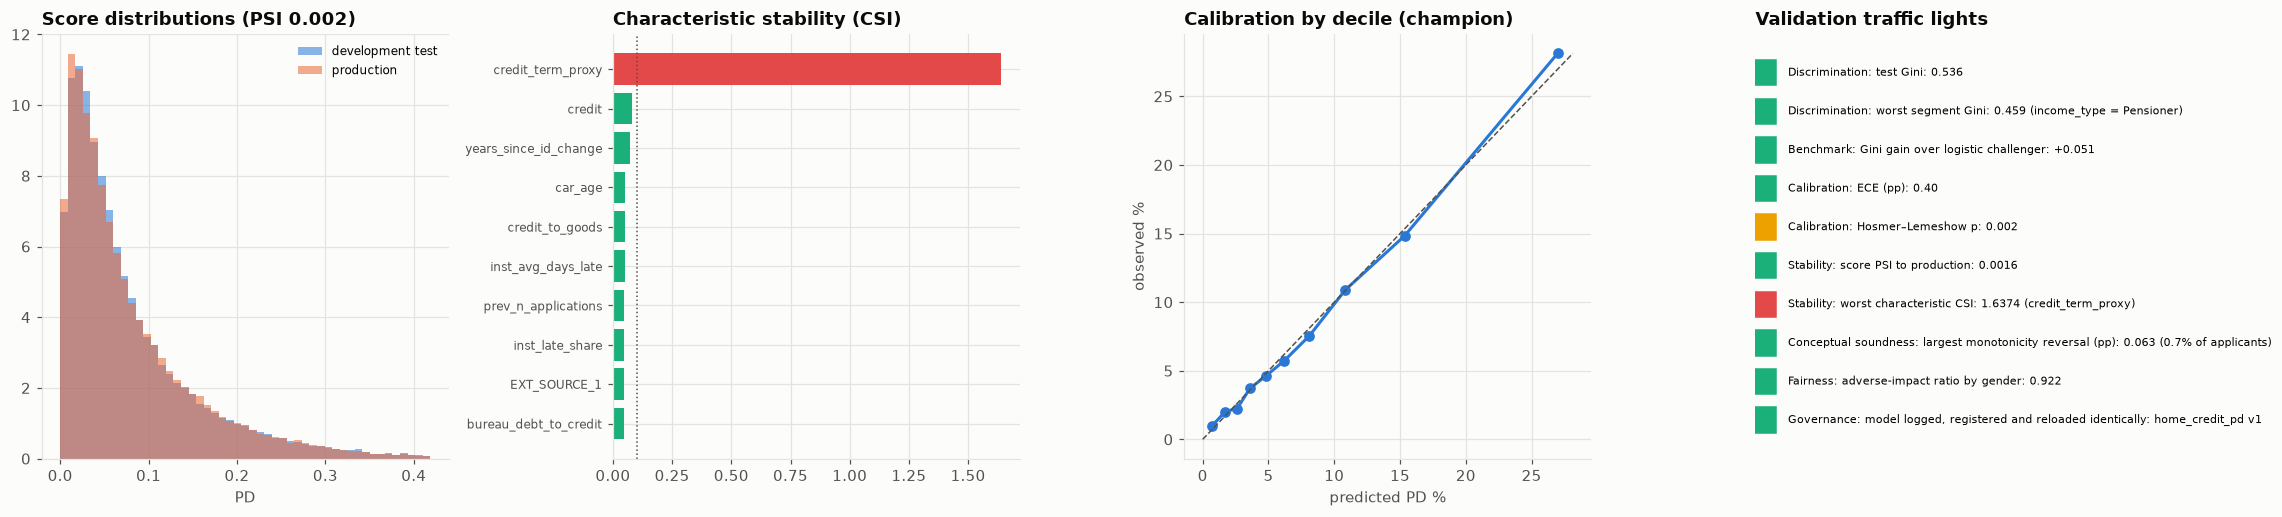

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
ax = axes[0]
bins_ = np.linspace(
    0, np.quantile(np.concatenate([p_te_c, p_prod]), 0.995), 50
)
ax.hist(
    p_te_c,
    bins_,
    density=True,
    alpha=0.55,
    color=PALETTE[0],
    label="development test",
)
ax.hist(
    p_prod,
    bins_,
    density=True,
    alpha=0.55,
    color=PALETTE[1],
    label="production",
)
ax.set_title(f"Score distributions (PSI {score_psi:.3f})")
ax.set_xlabel("PD")
ax.legend(fontsize=8)
ax = axes[1]
top = csi.head(10).iloc[::-1]
ax.barh(
    top.index,
    top.values,
    color=[
        STATUS[light(v, *THRESH["psi"], higher_is_better=False)]
        for v in top.values
    ],
)
ax.axvline(0.10, color=INK_2, ls=":", lw=1)
ax.set_title("Characteristic stability (CSI)")
ax.tick_params(axis="y", labelsize=8)
ax = axes[2]
q = pd.qcut(p_te_c, 10, labels=False)
g = pd.DataFrame({"p": p_te_c, "y": y_te, "q": q}).groupby("q").mean() * 100
ax.plot(g["p"], g["y"], "o-", color=PALETTE[0])
ax.plot([0, g.values.max()], [0, g.values.max()], color=INK_2, ls="--", lw=1)
ax.set_title("Calibration by decile (champion)")
ax.set_xlabel("predicted PD %")
ax.set_ylabel("observed %")
ax = axes[3]
ax.axis("off")
colors = summary["status"].map(STATUS).tolist()
for i, (t, r) in enumerate(summary.iterrows()):
    y0 = 1 - (i + 1) / (len(summary) + 1)
    ax.add_patch(
        plt.Rectangle(
            (0, y0 - 0.03), 0.05, 0.06, color=colors[i], transform=ax.transAxes
        )
    )
    ax.text(
        0.08,
        y0,
        f"{t}: {r['value']}",
        fontsize=7.5,
        va="center",
        transform=ax.transAxes,
    )
ax.set_title("Validation traffic lights")
plt.tight_layout()
save_fig(fig, "01_stability_calibration_traffic_lights")
plt.show()

## 8. Reading the results and limitations

The champion is a monotonic LightGBM with Platt calibration (22 features) and the challenger a logistic regression. The development sample has 307,511 applications, and "production" 48,744 new ones.

**Discrimination passes clearly.** The champion's test Gini is **0.536** (95% CI 0.523–0.550), against 0.485 for the challenger, a gain of +0.051 (CI +0.045 to +0.057).

By segment it ranges from 0.459 (pensioners) to 0.537 (employees). Every segment is above the 0.40 green line, but pensioners are the weakest and would be named in the monitoring plan.

**Calibration is good overall, imperfect in places.** The mean PD is 8.09% against an 8.07% default rate, with an ECE of 0.40 points (green).

Hosmer–Lemeshow still rejects (p = 0.002), because with 61,000 test applications the test picks up deviations of a fraction of a point. The segment view shows where they are.

State servants are predicted at 7.0% but default at 4.8%, so their PDs are 2.2 points too high. That costs pricing and approvals for a safe group. The finding is **amber**: recalibrate by segment or add an occupation-group offset.

**The production population looks like development, except for one characteristic.** The score PSI is only **0.0016**, and the mean PD moves from 8.09% to 8.01%.

But the characteristic stability index flags the implied loan term (credit / annuity) at **1.64**, far above the 0.25 red line. In production the median credit-to-annuity ratio is 16, against 20 in development, and cash loans are 99% of applications instead of 90%. The new applications are shorter cash loans with larger instalments.

The score does not move because that feature carries little weight and other shifts offset it. This is the textbook reason to monitor **CSI as well as PSI**: a stable score can hide a changed population. The model's performance on short-term cash loans should be checked as soon as outcomes mature.

**Conceptual soundness holds, with a footnote.** In the stress tests, lower external scores, higher instalment burdens and more late payments always raise the PD, for every applicant (+1.4, +0.2 and +0.8 points on average).

The ICE test still finds tiny reversals for 0.7% of applicants, at most 0.063 points of PD, on features with missing values, where LightGBM's constraint enforcement is not exact. They are below the 0.1-point materiality threshold, so they are documented rather than fixed.

Income is unconstrained: a 20% rise lowers the PD for 38% of applicants and raises it for the rest. A validator would ask for either a constraint or an explanation.

**Fairness and governance pass.** At an 80% approval rate, women and men are approved within an adverse-impact ratio of 0.92.

The champion is logged with its signature, registered as `home_credit_pd` v1 with the alias `champion`, and reloaded from the registry to score production with identical predictions. That is the audit trail SR 11-7 expects. The model card in `outputs/model_card.md` is generated from the same numbers.

**Overall opinion: approve with findings.** Two findings would go back to the developer: the drift in the loan-term characteristic, to monitor and test as outcomes arrive, and the miscalibration for state servants, to correct before the PDs are used for pricing.

**Limitations**

- There are no application dates, so there is no out-of-time test. The production file has no outcomes, so only stability, not performance, can be monitored there.
- The MLflow store is local (SQLite in `data/`). In production it would be a shared tracking server with access control and approval workflows on the registry.
- The thresholds are typical industry values, not a specific institution's policy.

In [10]:
disc.to_csv(OUT_DIR / "discrimination_calibration.csv")
csi.rename("CSI").to_csv(OUT_DIR / "characteristic_stability.csv")
segments.to_csv(OUT_DIR / "segment_performance.csv")
sens.to_csv(OUT_DIR / "sensitivity.csv")
summary.to_csv(OUT_DIR / "validation_traffic_lights.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_stability_calibration_traffic_lights.png, characteristic_stability.csv, discrimination_calibration.csv, model_card.md, segment_performance.csv, sensitivity.csv, validation_traffic_lights.csv


## References

### Finance and regulation

- Board of Governors of the Federal Reserve System. (2011). *Supervisory guidance on model risk management* (SR 11-7). https://www.federalreserve.gov/boarddocs/srletters/2011/sr1107.htm
- Basel Committee on Banking Supervision. (2005). *Studies on the validation of internal rating systems* (Working Paper No. 14). Bank for International Settlements. https://www.bis.org/publ/bcbs_wp14.htm
- Siddiqi, N. (2017). *Intelligent credit scoring: Building and implementing better credit risk scorecards* (2nd ed.). Wiley. https://doi.org/10.1002/9781119282396
- Hosmer, D. W., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied logistic regression* (3rd ed.). Wiley. https://doi.org/10.1002/9781118548387

### Machine learning and deep learning

- DeLong, E. R., DeLong, D. M., & Clarke-Pearson, D. L. (1988). Comparing the areas under two or more correlated receiver operating characteristic curves: A nonparametric approach. *Biometrics, 44*(3), 837–845. https://doi.org/10.2307/2531595
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Goldstein, A., Kapelner, A., Bleich, J., & Pitkin, E. (2015). Peeking inside the black box: Visualizing statistical learning with plots of individual conditional expectation. *Journal of Computational and Graphical Statistics, 24*(1), 44–65. https://doi.org/10.1080/10618600.2014.907095
- Mitchell, M., Wu, S., Zaldivar, A., Barnes, P., Vasserman, L., Hutchinson, B., … Gebru, T. (2019). Model cards for model reporting. In *Proceedings of the Conference on Fairness, Accountability, and Transparency*. https://doi.org/10.1145/3287560.3287596